# Optimising rating factors with `open-rating-engine`

This notebook takes the motor rating algorithm built in `01_rating_algorithm_example.ipynb` and re-tunes the multipliers in its `risk.demand_multiplier` rating tables, to maximise expected profit while holding the conversion rate where it is today.

| Step | What it does |
|---|---|
| Baseline | Loads the saved pipeline and scores a book of new-business quotes |
| Simulate | Re-scores the book across a grid of price multipliers, recording conversion and profit for every vehicle at every price point |
| Optimise | `PriceOptimizerRatingFactor` searches for one multiplier per rating-table row, reading each vehicle's response from the grid |
| Efficient frontier | Repeats the optimisation across a range of conversion targets, to show the profit/volume trade-off |
| Deploy | Writes the optimised multipliers back into the pipeline as a `RatingTablesLayer`, re-scores the book and saves the pipeline |

The optimiser never calls the pipeline itself. All the expensive scoring happens once, in the simulation step, and the optimiser interpolates between those results. The deploy step re-scores the book with the optimised tables, to check that interpolation against the real pipeline.

**Prerequisites**

- Run `01_rating_algorithm_example.ipynb` first. It saves the baseline pipeline to `models/rating_engines/pricing_pipeline.pkl`.
- Install the package with the ONNX, H2O and notebook extras. From the `open-rating-engine` folder: `pip install -e ".[onnx,h2o,notebook]"`
- Java 8+ installed, with `JAVA_HOME` set. The demand model is an H2O MOJO, scored in a JVM.
- Run the notebook from the `.examples` folder, so the `data/` and `models/` folders resolve.

In [1]:
from copy import deepcopy
from pathlib import Path

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlflow.pyfunc import PythonModelContext

from open_rating_engine.optimization import PriceOptimizerRatingFactor, make_log_multiplier_regularizer

# Imported from the submodule: once it's loaded, the package attribute of the same
# name resolves to the module rather than the function.
from open_rating_engine.optimization.simulate_adjustment_grid import (
    make_demand_emulation,
    simulate_adjustment_grid,
)

## 1. Input data

The origination book: every policy is a new-business quote (`policy.transaction_type == "NB"`), so none of them has a previous premium and the renewal cap/cup in the pipeline never applies. Each vehicle's premium therefore moves in direct proportion to its demand multiplier.

In [2]:
DATA_DIR = Path("data").resolve() / "origination"

data = {
    table: pd.read_parquet(DATA_DIR / f"{table}.parquet")
    for table in ["policy", "risk", "cover", "claims_history"]
}

pd.DataFrame({"rows": {table: len(df) for table, df in data.items()}})

,rows
policy,3691
risk,32253
cover,36967
claims_history,18455


In [3]:
data["policy"]["policy.transaction_type"].value_counts()

policy.transaction_type
NB    3691
Name: count, dtype: int64

## 2. Baseline rating engine

The pipeline was saved with `cloudpickle`, so it holds its layers, catalog and data structure, but not its loaded models. The ONNX and H2O layers reload their model files in `load_context`.

The saved pipeline also holds the context it was built with, whose artifact paths are absolute paths on the machine that ran notebook 01. Building a fresh context from this folder keeps the notebook portable.

In [4]:
MODELS_DIR = Path("models").resolve()
BASELINE_PATH = MODELS_DIR / "rating_engines" / "pricing_pipeline.pkl"

with BASELINE_PATH.open("rb") as file:
    pricing_engine = cloudpickle.load(file)

artifacts = {
    "motor_risk_cost_onnx": MODELS_DIR / "motor_risk_cost_onnx" / "pipeline_onnx.onnx",
    "motor_demand_mojo": MODELS_DIR / "motor_demand_h2o" / "model.zip",
    "h2o_gen_model": MODELS_DIR / "motor_demand_h2o" / "h2o-genmodel.jar",
}
missing = [key for key, path in artifacts.items() if not path.exists()]
assert not missing, f"Model files not found for {missing}. Run this notebook from open-rating-engine/.examples."

context = PythonModelContext(
    artifacts={key: str(path) for key, path in artifacts.items()},
    model_config={"environment": "local", "java_options": "-Xmx1g"},
)
pricing_engine.load_context(context)

# The grid below scores the book many times over; one progress bar per score is noise.
pricing_engine.options["show_progress"] = False

print(f"{len(pricing_engine.get_layer_names())} layers loaded")

c:\git\bhavek-jamnadas\asterisk-core\.venv\Lib\site-packages\mlflow\pyfunc\model.py:209: UserWarning: Type hint used in the model's predict function is not supported for MLflow's schema validation. Type hints must be wrapped in list[...] because MLflow assumes the predict method to take multiple input instances. Specify your type hint as `list[typing.Dict[str, pandas.core.frame.DataFrame]]` for a valid signature. Remove the type hint to disable this warning. To enable validation for the input data, specify input example or model signature when logging the model. 
  func_info = _get_func_info_if_type_hint_supported(predict_attr)
Load Context: Adding Artifact - motor_risk_cost_onnx
Load Context: Adding Artifact - motor_demand_mojo
Load Context: Adding Artifact - h2o_gen_model
Load Context: Starting JVM...
Load Context: {'motor_risk_cost_onnx': 'C:/git/bhavek-jamnadas/open-rating-engine/.examples/models/motor_risk_cost_onnx/pipeline_onnx.onnx', 'motor_demand_mojo': 'C:/git/bhavek-jamnadas

57 layers loaded


### The rating factors to optimise

`risk.demand_multiplier` is a `RatingTablesLayer` with two tables, youngest-driver age band and customer tenure band. Its formula multiplies them, so a vehicle's multiplier is its age-band value × its tenure-band value. Every value is 1.0 in the baseline, so these 9 rows are the decision variables.

In [5]:
LAYER_NAME = "risk.demand_multiplier"

demand_layer = pricing_engine.layers[LAYER_NAME]
print(f"formula: {demand_layer.formula}")
print(f"default_values: {demand_layer.default_values}")

for name, table in demand_layer.rating_tables.items():
    print(f"\n{name}")
    display(table)

formula: risk_age_band['value'] * customer_tenure_band['value']
default_values: {'risk_age_band': 1.0, 'customer_tenure_band': 1.0}

risk_age_band


,risk.risk_age_band,value
0,15-24,1.0
1,25-34,1.0
2,35-44,1.0
3,45-54,1.0
4,55-64,1.0
5,65+,1.0



customer_tenure_band


,risk.customer_tenure_band,value
0,0-5,1.0
1,6-10,1.0
2,10+,1.0


### Score the baseline

In [6]:
baseline_output = pricing_engine.predict(data)

with pd.option_context("display.max_columns", None):
    display(baseline_output["risk"].head(10))

,risk.policy_number,risk.risk_number,risk.driver_youngest_dob,risk.driver_youngest_age,risk.driver_youngest_gender,risk.driver_youngest_occupation,risk.vehicle_usage,risk.average_mileage,risk.basic_excess,risk.vehicle_market_value,risk.vehicle_make,risk.vehicle_fuel_type,risk.vehicle_age,risk.claims_history_claim_count_5_years,risk.location_geoid,risk.location_statefp,risk.location_population,risk.location_proportion_white,risk.location_latitude,risk.location_longitude,risk.previous_gwp,risk.competitor_premiums_average,risk.gwp,risk.transaction_type,risk.customer_tenure,risk.risk_age_band,risk.demand_multiplier_individual,cat_onehot__risk_usage_Private,cat_onehot__risk_usage_Rideshare,risk.reporting_previous_gwp,cat_onehot__transaction_type_RN,risk.customer_tenure_band,risk.cover_flag_hire_car,risk.demand_multiplier,risk.pred_claim_cost,customer_tenure_band,cap_percentage,cup_percentage,cap_percentage_filled,cup_percentage_filled,risk.policy_pred_claim_cost,risk.premium_stat_prem_risk_cost,risk.premium_stat_prem_administration_expense,risk.premium_stat_prem_claims_handling_expense,risk.premium_stat_prem_commission_expense,risk.premium_stat_prem_reinsurance_expense,risk.premium_stat_prem_investment_income,risk.premium_stat_prem_target_profit_margin,risk.premium_stat_prem_total,risk.premium_demand_total,risk.reporting_offered_technical_premium,risk.premium_comm_prem_cap_cup,risk.premium_final,risk.reporting_offered_gwp,num__distance_to_competitor_percent,num__distance_to_competitor_abs,num__price_change,num__gwp,risk.reporting_offered_profit,risk.reporting_offered_loss_ratio,risk.reporting_offered_premium_change,risk.conversion_rate,risk.reporting_offered_profit_margin,risk.reporting_expected_gwp,risk.reporting_expected_technical_premium,risk.reporting_expected_profit,risk.reporting_expected_profit_margin
0,c22591ed41_NB,cdf6c3a288_NB,1956-12-09,63,Female,Artist,Commercial,5000,500,19029.17,Hyundai,Diesel,18,0,6037,6,10039107,0.707066,34.320743,-118.224810,NaN,1136.847606,552.099371,NB,0,55-64,1.0,0,0,NaN,0,0-5,0,1.0,394.385406,0-5,0.5,-0.05,0.5,-0.05,4133.048828,407.777240,83.155545,20.388862,20.388862,0.0,-20.388862,40.777724,552.099371,552.099371,552.099371,552.099371,552.099371,552.099371,-0.514359,584.748235,NaN,552.099371,0.0,1.0,NaN,0.804727,0.0,444.289531,444.289531,0.0,0.0
1,f44ffa7063_NB,0daa59c822_NB,1991-12-03,29,Female,Engineer,Rideshare,5000,1000,33686.11,Honda,Diesel,20,0,6073,6,3338330,0.754086,33.034137,-116.735293,NaN,1918.488008,1856.310092,NB,4,25-34,1.0,0,1,NaN,0,0-5,0,1.0,1557.219116,0-5,0.5,-0.05,0.5,-0.05,8514.122070,1522.487258,105.449745,76.124363,76.124363,0.0,-76.124363,152.248726,1856.310092,1856.310092,1856.310092,1856.310092,1856.310092,1856.310092,-0.032410,62.177916,NaN,1856.310092,0.0,1.0,NaN,0.127099,0.0,235.935105,235.935105,0.0,0.0
2,5bcc83eeae_NB,c43da7ccea_NB,1960-01-16,65,Male,Teacher,Commercial,15000,1000,26463.06,Ford,Hybrid,9,0,51059,51,1147532,0.646760,38.836840,-77.276988,NaN,1268.932310,1168.244249,NB,0,55-64,1.0,0,0,NaN,0,0-5,0,1.0,952.856750,0-5,0.5,-0.05,0.5,-0.05,9868.221680,934.396794,93.687936,46.719840,46.719840,0.0,-46.719840,93.439679,1168.244249,1168.244249,1168.244249,1168.244249,1168.244249,1168.244249,-0.079349,100.688061,NaN,1168.244249,0.0,1.0,NaN,0.190030,0.0,222.001308,222.001308,0.0,0.0
3,034832413c_NB,dc761835aa_NB,1981-07-27,43,Male,Retired,Private,15000,1000,44561.46,BMW,Electric,13,0,4013,4,4485414,0.827994,33.348816,-112.491291,NaN,1347.433073,2218.173648,NB,0,35-44,1.0,1,0,NaN,0,0-5,0,1.0,1880.842773,0-5,0.5,-0.05,0.5,-0.05,13919.182617,1831.772349,111.635447,91.588617,91.588617,0.0,-91.588617,183.177235,2218.173648,2218.173648,2218.173648,2218.173648,2218.173648,2218.173648,0.646222,870.740575,NaN,2218.173648,0.0,1.0,NaN,0.019199,0.0,42.587398,42.587398,0.0,0.0
4,d9cd070b29_NB,35790b6361_NB,1967-05-24,56,Male,Artist,Commercial,15000,250,52178.62,Mercedes,Hybrid,22,2,25009,25,789034,0.850592,42.673092,-70.951967,NaN,3939.866873,2820.328446,NB,6,55-64,1.0,0,0,N

Book-level KPIs, as averages per vehicle. *Expected* figures are weighted by the probability that the customer accepts the quote, so expected profit is the profit the book makes once the quotes that don't convert are taken out.

In [7]:
KPI_COLUMNS = {
    "Offered GWP": "risk.gwp",
    "Conversion rate": "risk.conversion_rate",
    "Expected GWP": "risk.reporting_expected_gwp",
    "Expected profit": "risk.reporting_expected_profit",
}


def book_kpis(scored):
    risk = scored["risk"]
    kpis = {label: risk[column].mean() for label, column in KPI_COLUMNS.items()}
    kpis["Expected profit margin"] = kpis["Expected profit"] / kpis["Expected GWP"]
    return pd.Series(kpis)


baseline_kpis = book_kpis(baseline_output)
baseline_kpis.to_frame("Baseline").round(4)

,Baseline
Offered GWP,1232.7234
Conversion rate,0.3498
Expected GWP,331.4460
Expected profit,27.6908
Expected profit margin,0.0835


## 3. Simulate the price response

`simulate_adjustment_grid` scores the book once for each adjustment factor and returns an `(N, K)` array for every requested column: one row per vehicle, one column per factor.

How the factor reaches the pipeline is up to the `premium_emulation` callback. `make_demand_emulation` builds one that drives a single rating table of the demand layer. In `"override"` mode it sets every value in `risk_age_band`, and that table's default, to the factor. The tenure table is all 1.0, so the layer's output equals the factor on every vehicle, and each column of the grid is the book priced at `factor ×` its baseline premium.

**Choosing the grid.** The optimiser looks up each vehicle's response at its *effective* multiplier, the product of its age-band and tenure-band values. With each value bounded to `[0.9, 1.1]`, the product ranges over `[0.81, 1.21]`, so the grid runs from 0.80 to 1.25. Outside the grid, the interpolation holds the end values flat, so a grid narrower than the reachable range would hide the price response at the extremes.

Each factor is scored on a deep copy of the pipeline, in parallel threads.

In [8]:
OUTPUT_COLUMNS = {
    "gwp": "risk.gwp",
    "conversion_rate": "risk.conversion_rate",
    "expected_gwp": "risk.reporting_expected_gwp",
    "expected_profit": "risk.reporting_expected_profit",
}

premium_emulation = make_demand_emulation(
    layer_name=LAYER_NAME,
    table_key="risk_age_band",
    mode="override",
)

simulated = simulate_adjustment_grid(
    data=data,
    pipeline=pricing_engine,
    premium_emulation=premium_emulation,
    output_table="risk",
    output_columns=OUTPUT_COLUMNS,
    adjustment_factor=np.round(np.arange(0.80, 1.2501, 0.05), 2),
    parallel_n_jobs=5,
)

factors = simulated["adjustment_factor_array"]
print(f"factors: {factors}")
print(f"conversion_rate array: {simulated['conversion_rate'].shape} (vehicles x factors)")

scoring adjustment factors:   0%|          | 0/10 [00:04<?, ?it/s]

factors: [0.8  0.85 0.9  0.95 1.   1.05 1.1  1.15 1.2  1.25]
conversion_rate array: (32253, 10) (vehicles x factors)


Averaging the grid over the book gives the response to a **uniform** price change: every vehicle's premium moved by the same factor. The 1.00 column reproduces the baseline KPIs.

In [9]:
uniform_response = pd.DataFrame(
    {name: simulated[name].mean(axis=0) for name in OUTPUT_COLUMNS},
    index=pd.Index(factors, name="adjustment_factor"),
)


def at_factor(factor):
    # Book-average KPIs when every premium is scaled by `factor`.
    return uniform_response.loc[np.isclose(uniform_response.index, factor)].iloc[0]


current_conversion = at_factor(1.0)["conversion_rate"]
print(f"Current conversion: {current_conversion:.2%}")

uniform_response.round(4)

Current conversion: 34.98%


,gwp,conversion_rate,expected_gwp,expected_profit
adjustment_factor,,,,
0.80,1063.0204,0.4952,438.4572,-29.5438
0.85,1104.5674,0.4574,411.3067,-10.2403
0.90,1146.8712,0.4202,384.2005,5.4538
0.95,1189.6977,0.3842,357.4737,17.9755
1.00,1232.7234,0.3498,331.4460,27.6908
1.05,1275.5291,0.3173,306.5104,34.9298
1.10,1317.8316,0.2874,283.3054,40.0750
1.15,1359.5493,0.2601,261.6849,43.5099
1.20,1400.4963,0.2354,241.8484,45.5569


## 4. Optimise

### Objective and regularisation

The optimiser maximises the book-average of `objective_array`, here each vehicle's expected profit, and holds the book-average of `constraint_array` (conversion rate) at a target.

A `regularizer` is subtracted from the objective to keep the solution close to the current rates. `make_log_multiplier_regularizer` penalises `l1 · |log m| + l2 · (log m)²` for every multiplier `m`. The penalty is in the objective's units (dollars of expected profit per vehicle), and treats a 5% increase and the matching decrease alike. Both weights are 0 here, so the optimiser is unconstrained within its bounds. Raise them to trade some profit for smaller rate moves.

In [10]:
regularizer = make_log_multiplier_regularizer(l1_penalty=0.0, l2_penalty=0.0)

### Build the optimiser from the pipeline

`from_pipeline` reads the decision space straight from the layer: each rating table becomes one rating factor, its rows become the categories, and the current values seed the search. It maps every vehicle in `scored_data` to its row in each table, and holds vehicles that match no row at the table's default.

In [11]:
optimizer = PriceOptimizerRatingFactor.from_pipeline(
    pipeline=pricing_engine,
    layer_name=LAYER_NAME,
    scored_data=baseline_output,
    adjustment_factors=factors,
    objective_array=simulated["expected_profit"],
    constraint_array=simulated["conversion_rate"],
    reporting_arrays={
        "gwp": simulated["gwp"],
        "expected_gwp": simulated["expected_gwp"],
    },
    regularizer=regularizer,
)

### Maximise profit at today's conversion rate

`optimize` supports three `scipy` methods:

- `"SLSQP"` enforces the conversion target as an equality constraint.
- `"L-BFGS-B"` and `"Nelder-Mead"` add `constraint_penalty_weight × (conversion − target)²` to the objective instead.

Nelder-Mead is used here, with a large penalty weight to hold conversion close to the target.

In [12]:
BOUNDS = (0.9, 1.1)

result = optimizer.optimize(
    target_constraint=float(current_conversion),
    bounds=BOUNDS,
    method="Nelder-Mead",
    constraint_penalty_weight=1e6,
)

result["summary"].T

,0
target_constraint,0.349764
constraint,0.349626
objective,27.766409
price_multiplier,1.000609
gwp,1232.984277
expected_gwp,331.466647
method,Nelder-Mead
constraint_gap,-0.000138
result_success,True
result_message,Optimization terminated successfully.


`to_rating_tables` decodes the optimal multipliers back into the layer's table format, with the original key column and a `value` column.

In [13]:
optimized_tables = optimizer.to_rating_tables()

for name, table in optimized_tables.items():
    exposure = baseline_output["risk"][table.columns[0]].value_counts().rename("vehicles")
    print(f"\n{name}")
    display(table.join(exposure, on=table.columns[0]).round(4))


risk_age_band


,risk.risk_age_band,value,vehicles
0,15-24,1.0023,3506
1,25-34,1.0003,5372
2,35-44,0.9960,5284
3,45-54,1.0023,5472
4,55-64,1.0012,5803
5,65+,1.0023,6816



customer_tenure_band


,risk.customer_tenure_band,value,vehicles
0,0-5,0.9977,26865
1,6-10,1.0000,4380
2,10+,1.0567,1008


## 5. Efficient frontier

Re-running the optimisation across a range of conversion targets traces the most expected profit available at each level of conversion. The range runs from the conversion of a uniform 15% price increase to that of a uniform 15% decrease. Further out, a target needs nearly every multiplier at its bound, which leaves the optimiser no room to move.

In [14]:
target_range = np.linspace(at_factor(1.15)["conversion_rate"], at_factor(0.85)["conversion_rate"], 9)

frontier = optimizer.calculate_efficient_frontier(
    target_constraint_range=target_range,
    bounds=BOUNDS,
    method="SLSQP",
)

frontier[["target_constraint", "constraint", "objective", "price_multiplier", "gwp", "expected_gwp", "result_nit"]].round(4)

Optimising rating factors:   0%|          | 0/9 [00:00<?, ?it/s]

,target_constraint,constraint,objective,price_multiplier,gwp,expected_gwp,result_nit
0,0.2601,0.2601,43.5562,1.1506,1359.7207,261.7724,42
1,0.2847,0.2847,40.5544,1.1058,1321.9195,281.4079,41
2,0.3094,0.3094,36.4871,1.0650,1286.8189,300.7614,40
3,0.3341,0.3341,31.3857,1.0266,1254.7158,319.7404,73
4,0.3587,0.3587,25.1151,0.9868,1221.7821,338.1052,35
5,0.3834,0.3834,16.8554,0.9520,1193.9151,355.7703,16
6,0.4081,0.4081,9.8677,0.9172,1159.5406,375.9181,91
7,0.4328,0.4328,-0.5820,0.8824,1130.5066,393.8143,33
8,0.4574,0.4574,-10.2363,0.8499,1104.0199,411.5027,50


The chart compares the frontier with the uniform price change from section 3. A uniform change is always a feasible solution, so the frontier should sit on or above the uniform line. Wherever it falls below, the optimiser stopped short of the best solution for that target.

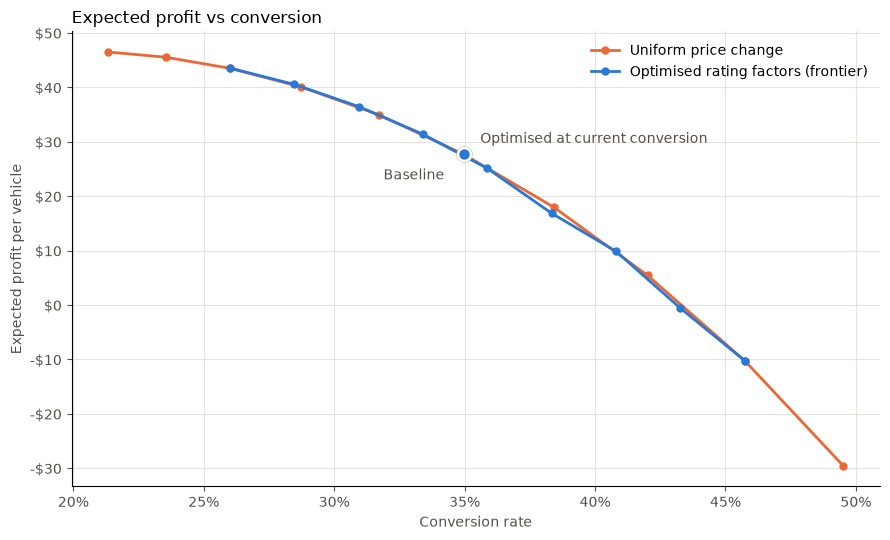

In [15]:
UNIFORM_COLOR = "#eb6834"
FRONTIER_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"

optimized = result["summary"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    uniform_response["conversion_rate"],
    uniform_response["expected_profit"],
    color=UNIFORM_COLOR, linewidth=2, marker="o", markersize=5,
    label="Uniform price change",
)
ax.plot(
    frontier["constraint"],
    frontier["objective"],
    color=FRONTIER_COLOR, linewidth=2, marker="o", markersize=5,
    label="Optimised rating factors (frontier)",
)
ax.scatter(
    [current_conversion], [baseline_kpis["Expected profit"]],
    s=90, color="white", edgecolor=TEXT_COLOR, linewidth=2, zorder=3,
)
ax.annotate(
    "Baseline", (current_conversion, baseline_kpis["Expected profit"]),
    xytext=(-14, -18), textcoords="offset points", ha="right", color=TEXT_COLOR,
)
ax.scatter(
    [optimized["constraint"]], [optimized["objective"]],
    s=90, color=FRONTIER_COLOR, edgecolor="white", linewidth=2, zorder=4,
)
ax.annotate(
    "Optimised at current conversion", (optimized["constraint"], optimized["objective"]),
    xytext=(12, 8), textcoords="offset points", color=TEXT_COLOR,
)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"-${-y:,.0f}" if y < 0 else f"${y:,.0f}"))
ax.set_xlabel("Conversion rate", color=TEXT_COLOR)
ax.set_ylabel("Expected profit per vehicle", color=TEXT_COLOR)
ax.set_title("Expected profit vs conversion", loc="left")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors=TEXT_COLOR)
ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()

## 6. Deploy the optimised rating factors

`to_layer` rebuilds the `RatingTablesLayer` from the optimised tables, keeping the original layer's name, formula, defaults, dependencies and output column. Swapping it into a copy of the pipeline leaves the baseline untouched for comparison.

In [16]:
optimized_engine = deepcopy(pricing_engine)
optimized_engine.remove_parameter(LAYER_NAME)
optimized_engine.add_parameter(optimizer.to_layer())

for name, table in optimized_engine.layers[LAYER_NAME].rating_tables.items():
    print(f"\n{name}")
    display(table.round(4))


risk_age_band


,risk.risk_age_band,value
0,15-24,1.0023
1,25-34,1.0003
2,35-44,0.9960
3,45-54,1.0023
4,55-64,1.0012
5,65+,1.0023



customer_tenure_band


,risk.customer_tenure_band,value
0,0-5,0.9977
1,6-10,1.0000
2,10+,1.0567


### Re-score the book

Scoring with the real pipeline checks the optimiser's interpolated estimate. The two agree closely because the premium is proportional to the multiplier on new business, and the grid is fine enough for linear interpolation between its points to track the demand model.

In [17]:
optimized_output = optimized_engine.predict(data)

with pd.option_context("display.max_columns", None):
    display(optimized_output["risk"].head(10))

,risk.policy_number,risk.risk_number,risk.driver_youngest_dob,risk.driver_youngest_age,risk.driver_youngest_gender,risk.driver_youngest_occupation,risk.vehicle_usage,risk.average_mileage,risk.basic_excess,risk.vehicle_market_value,risk.vehicle_make,risk.vehicle_fuel_type,risk.vehicle_age,risk.claims_history_claim_count_5_years,risk.location_geoid,risk.location_statefp,risk.location_population,risk.location_proportion_white,risk.location_latitude,risk.location_longitude,risk.previous_gwp,risk.competitor_premiums_average,risk.gwp,risk.transaction_type,risk.customer_tenure,risk.risk_age_band,risk.demand_multiplier_individual,cat_onehot__risk_usage_Private,cat_onehot__risk_usage_Rideshare,risk.reporting_previous_gwp,cat_onehot__transaction_type_RN,risk.customer_tenure_band,risk.cover_flag_hire_car,risk.demand_multiplier,risk.pred_claim_cost,customer_tenure_band,cap_percentage,cup_percentage,cap_percentage_filled,cup_percentage_filled,risk.policy_pred_claim_cost,risk.premium_stat_prem_risk_cost,risk.premium_stat_prem_administration_expense,risk.premium_stat_prem_claims_handling_expense,risk.premium_stat_prem_commission_expense,risk.premium_stat_prem_reinsurance_expense,risk.premium_stat_prem_investment_income,risk.premium_stat_prem_target_profit_margin,risk.premium_stat_prem_total,risk.premium_demand_total,risk.reporting_offered_technical_premium,risk.premium_comm_prem_cap_cup,risk.premium_final,risk.reporting_offered_gwp,num__distance_to_competitor_percent,num__distance_to_competitor_abs,num__price_change,num__gwp,risk.reporting_offered_profit,risk.reporting_offered_loss_ratio,risk.reporting_offered_premium_change,risk.conversion_rate,risk.reporting_offered_profit_margin,risk.reporting_expected_gwp,risk.reporting_expected_technical_premium,risk.reporting_expected_profit,risk.reporting_expected_profit_margin
0,c22591ed41_NB,cdf6c3a288_NB,1956-12-09,63,Female,Artist,Commercial,5000,500,19029.17,Hyundai,Diesel,18,0,6037,6,10039107,0.707066,34.320743,-118.224810,NaN,1136.847606,551.485061,NB,0,55-64,1.0,0,0,NaN,0,0-5,0,0.998887,394.385406,0-5,0.5,-0.05,0.5,-0.05,4133.048828,407.777240,83.155545,20.388862,20.388862,0.0,-20.388862,40.777724,552.099371,551.485061,552.099371,551.485061,551.485061,551.485061,-0.514900,585.362545,NaN,551.485061,-0.614310,1.001114,NaN,0.804727,-0.001114,443.795179,444.289531,-0.494352,-0.001114
1,f44ffa7063_NB,0daa59c822_NB,1991-12-03,29,Female,Engineer,Rideshare,5000,1000,33686.11,Honda,Diesel,20,0,6073,6,3338330,0.754086,33.034137,-116.735293,NaN,1918.488008,1852.692837,NB,4,25-34,1.0,0,1,NaN,0,0-5,0,0.998051,1557.219116,0-5,0.5,-0.05,0.5,-0.05,8514.122070,1522.487258,105.449745,76.124363,76.124363,0.0,-76.124363,152.248726,1856.310092,1852.692837,1856.310092,1852.692837,1852.692837,1852.692837,-0.034295,65.795170,NaN,1852.692837,-3.617255,1.001952,NaN,0.132249,-0.001952,245.017263,245.495642,-0.478379,-0.001952
2,5bcc83eeae_NB,c43da7ccea_NB,1960-01-16,65,Male,Teacher,Commercial,15000,1000,26463.06,Ford,Hybrid,9,0,51059,51,1147532,0.646760,38.836840,-77.276988,NaN,1268.932310,1166.944367,NB,0,55-64,1.0,0,0,NaN,0,0-5,0,0.998887,952.856750,0-5,0.5,-0.05,0.5,-0.05,9868.221680,934.396794,93.687936,46.719840,46.719840,0.0,-46.719840,93.439679,1168.244249,1166.944367,1168.244249,1166.944367,1166.944367,1166.944367,-0.080373,101.987944,NaN,1166.944367,-1.299882,1.001114,NaN,0.194124,-0.001114,226.532490,226.784829,-0.252339,-0.001114
3,034832413c_NB,dc761835aa_NB,1981-07-27,43,Male,Retired,Private,15000,1000,44561.46,BMW,Electric,13,0,4013,4,4485414,0.827994,33.348816,-112.491291,NaN,1347.433073,2204.357146,NB,0,35-44,1.0,1,0,NaN,0,0-5,0,0.993771,1880.842773,0-5,0.5,-0.05,0.5,-0.05,13919.182617,1831.772349,111.635447,91.588617,91.588617,0.0,-91.588617,183.177235,2218.173648,2204.357146,2218.173648,2204.357146,2204.357146,2204.357146,0.635968,856.924073,NaN,2204.357146,-13.816502,1.006268,NaN,0.019491,-0.006268,42.965968,43.235270,-0.269303,-0.006268
4,d9cd070b29_NB,35790b6361_NB,1967-05-24,56,Male,Artist,Commerci

In [18]:
optimized_kpis = book_kpis(optimized_output)

comparison = pd.DataFrame({
    "Baseline": baseline_kpis,
    "Optimised (re-scored)": optimized_kpis,
    "Optimiser estimate": {
        "Offered GWP": optimized["gwp"],
        "Conversion rate": optimized["constraint"],
        "Expected GWP": optimized["expected_gwp"],
        "Expected profit": optimized["objective"],
        "Expected profit margin": optimized["objective"] / optimized["expected_gwp"],
    },
})
comparison["Change vs baseline"] = comparison["Optimised (re-scored)"] / comparison["Baseline"] - 1
comparison.round(4)

,Baseline,Optimised (re-scored),Optimiser estimate,Change vs baseline
Offered GWP,1232.7234,1232.9892,1232.9843,0.0002
Conversion rate,0.3498,0.3495,0.3496,-0.0007
Expected GWP,331.4460,331.3797,331.4666,-0.0002
Expected profit,27.6908,27.8081,27.7664,0.0042
Expected profit margin,0.0835,0.0839,0.0838,0.0044


In [19]:
print(f"Conversion:      {baseline_kpis['Conversion rate']:.2%} -> {optimized_kpis['Conversion rate']:.2%}")
print(f"Expected profit: ${baseline_kpis['Expected profit']:.2f} -> ${optimized_kpis['Expected profit']:.2f} per vehicle "
      f"({optimized_kpis['Expected profit'] / baseline_kpis['Expected profit'] - 1:+.2%})")
print(f"Profit margin:   {baseline_kpis['Expected profit margin']:.2%} -> {optimized_kpis['Expected profit margin']:.2%}")

Conversion:      34.98% -> 34.95%
Expected profit: $27.69 -> $27.81 per vehicle (+0.42%)
Profit margin:   8.35% -> 8.39%


### Results by rating factor

Book KPIs split by each rating factor show where the optimiser moved price, and how volume and profit shifted between the bands.

In [20]:
def kpis_by(scored, column, order):
    risk = scored["risk"]
    return risk.groupby(column, observed=True).agg(
        vehicles=("risk.risk_number", "count"),
        demand_multiplier=("risk.demand_multiplier", "mean"),
        conversion_rate=("risk.conversion_rate", "mean"),
        expected_profit=("risk.reporting_expected_profit", "mean"),
    ).reindex(order)


for name, table in optimized_tables.items():
    column = table.columns[0]
    print(f"\n{name}")
    display(
        pd.concat(
            {
                "Baseline": kpis_by(baseline_output, column, table[column]),
                "Optimised": kpis_by(optimized_output, column, table[column]),
            },
            axis=1,
        ).round(4)
    )


risk_age_band


Baseline                                                    \
                   vehicles demand_multiplier conversion_rate expected_profit   
risk.risk_age_band                                                              
15-24                  3506               1.0          0.1605         -5.7735   
25-34                  5372               1.0          0.3095         22.5161   
35-44                  5284               1.0          0.3449         30.2949   
45-54                  5472               1.0          0.3783         31.5929   
55-64                  5803               1.0          0.3807         30.0070   
65+                    6816               1.0          0.4333         41.8589   

                   Optimised                                                    
                    vehicles demand_multiplier conversion_rate expected_profit  
risk.risk_age_band                                                              
15-24                   3506            1.0023          0.1599         -5.5837  
25-34                   5372            1.0002          0.3096         22.5774  
35-44                   5284            0.9960          0.3477         29.6719  
45-54                   5472            1.0021          0.3770         31.9471  
55-64                   5803            1.0010          0.3800         30.2008  
65+                     6816            1.0021          0.4319         42.3020


customer_tenure_band


Baseline                                    \
                          vehicles demand_multiplier conversion_rate   
risk.customer_tenure_band                                              
0-5                          26865               1.0          0.3417   
6-10                          4380               1.0          0.3826   
10+                           1008               1.0          0.4212   

                                          Optimised                    \
                          expected_profit  vehicles demand_multiplier   
risk.customer_tenure_band                                               
0-5                               30.5944     26865            0.9985   
6-10                              16.8382      4380            1.0007   
10+                               -2.5404      1008            1.0575   

                                                           
                          conversion_rate expected_profit  
risk.customer_tenure_band                                  
0-5                                0.3428         30.3332  
6-10                               0.3819         16.9524  
10+                                0.3884          7.6819

## 7. Save the optimised pipeline

Saved with `cloudpickle` beside the baseline, in the same way as notebook 01. Load it with `cloudpickle.load` and call `load_context` before scoring.

In [21]:
OPTIMIZED_PATH = MODELS_DIR / "rating_engines" / "pricing_pipeline_rating_factor_optimized.pkl"

with OPTIMIZED_PATH.open("wb") as file:
    cloudpickle.dump(optimized_engine, file)

print(f"Pipeline saved to {OPTIMIZED_PATH}")

Pipeline saved to C:\git\bhavek-jamnadas\open-rating-engine\.examples\models\rating_engines\pricing_pipeline_rating_factor_optimized.pkl
